# Modelo XGBoost Multicanal

**Maestría en Inteligencia Artificial MAIA**

**Proyecto - Desarrollo de Soluciones**

***Estudiantes:***
- María José García (mj.garciab1@uniandes.edu.co)
- Daniel Osuna (d.osuna@uniandes.edu.co)
- Gabriel Vizcaya (g.vizcaya@uniandes.edu.co)
- Joel Vargas (js.vargasl1@uniandes.edu.co)

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import sys
import os

In [28]:
project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

DATA_DIR = project_root / "data/sleep-edfx/sleep-cassette" 

In [29]:
from src.data.loader import load_subject, load_psg, find_subject_pairs
from src.data.segmentation import (
    extract_epochs,
    trim_wake_edges,
    EpochDataset,
    concatenate_datasets,
    class_distribution,
    INT_TO_CLASS,
    concatenate_datasets_by_split
)
from src.preprocessing.feature_engineering import extract_features, to_dataframe, FREQ_BANDS

In [30]:
PSG_PATH = "SC4001E0-PSG.edf"
psg_file = DATA_DIR / PSG_PATH

raw_preview = load_psg(psg_file, verbose=False)

# El EDF puede declarar frecuencias por canal en el encabezado. MNE expone
# una frecuencia común en raw.info["sfreq"]; este bloque intenta recuperar
# la frecuencia original por señal desde el encabezado y usa sfreq como respaldo.
def get_channel_sampling_frequencies(raw):
    sampling_freqs = {ch: float(raw.info["sfreq"]) for ch in raw.ch_names}

    try:
        edf_header = raw._raw_extras[0]
        n_samps = np.asarray(edf_header.get("n_samps"), dtype=float)
        record_length = edf_header.get("record_length")
        record_duration = float(np.ravel(record_length)[0])

        if len(n_samps) == len(raw.ch_names) and record_duration > 0:
            sampling_freqs = {
                ch: float(n_sample / record_duration)
                for ch, n_sample in zip(raw.ch_names, n_samps)
            }
    except Exception as exc:
        print(f"No se pudo leer la frecuencia por canal del encabezado EDF; se usa sfreq global. Detalle: {exc}")

    return sampling_freqs

channel_sampling_freqs = get_channel_sampling_frequencies(raw_preview)

channels_df = pd.DataFrame({
    "canal": raw_preview.ch_names,
    "tipo": raw_preview.get_channel_types(),
    "frecuencia_hz": [channel_sampling_freqs[ch] for ch in raw_preview.ch_names],
    "n_muestras": [raw_preview.n_times] * len(raw_preview.ch_names),
    "duracion_min": [raw_preview.n_times / raw_preview.info["sfreq"] / 60] * len(raw_preview.ch_names),
})


/Users/joevargas/Documents/personal/Maestria Andes - IA/14_proyecto_desarrollo_soluciones/micro_proyecto/proyecto-desarrollo-de-soluciones-G5/src/data/loader.py:38: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  return mne.io.read_raw_edf(path, preload=False, verbose=verbose)
/Users/joevargas/Documents/personal/Maestria Andes - IA/14_proyecto_desarrollo_soluciones/micro_proyecto/proyecto-desarrollo-de-soluciones-G5/src/data/loader.py:38: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  return mne.io.read_raw_edf(path, preload=False, verbose=verbose)
/Users/joevargas/Documents/personal/Maestria Andes - IA/14_proyecto_desarrollo_soluciones/micro_proyecto/proyecto-desarrollo-de-soluciones-G5/src/data/loader.py:38: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  return mne.io.read_raw_edf(path, preload=Fals

In [31]:
print(f"Canales encontrados: {len(raw_preview.ch_names)}")
print(f"Frecuencia global reportada por MNE: {raw_preview.info['sfreq']} Hz")
display(channels_df)

Canales encontrados: 7
Frecuencia global reportada por MNE: 100.0 Hz


,canal,tipo,frecuencia_hz,n_muestras,duracion_min
0,EEG Fpz-Cz,eeg,100.0,7950000,1325.0
1,EEG Pz-Oz,eeg,100.0,7950000,1325.0
2,EOG horizontal,eeg,100.0,7950000,1325.0
3,Resp oro-nasal,eeg,1.0,7950000,1325.0
4,EMG submental,eeg,1.0,7950000,1325.0
5,Temp rectal,eeg,1.0,7950000,1325.0
6,Event marker,eeg,1.0,7950000,1325.0


In [37]:
HYPNO_PATH = "SC4001EC-Hypnogram.edf"

subject = load_subject(DATA_DIR / PSG_PATH, DATA_DIR / HYPNO_PATH)

epoch_ds = extract_epochs(
    subject.raw, subject.annotations,
    recording_id=subject.subject_id,
    channel_picks=["EEG Fpz-Cz", "EEG Pz-Oz", "EOG horizontal"],   # agrega más canales aquí si quieres, p.ej. ["EEG Fpz-Cz", "EEG Pz-Oz"]
)

print("X (señal cruda) shape:", epoch_ds.X.shape, " (n_epochs, n_channels, n_samples)")
print("Canales:", epoch_ds.channel_names)

/Users/joevargas/Documents/personal/Maestria Andes - IA/14_proyecto_desarrollo_soluciones/micro_proyecto/proyecto-desarrollo-de-soluciones-G5/src/data/loader.py:38: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  return mne.io.read_raw_edf(path, preload=False, verbose=verbose)
/Users/joevargas/Documents/personal/Maestria Andes - IA/14_proyecto_desarrollo_soluciones/micro_proyecto/proyecto-desarrollo-de-soluciones-G5/src/data/loader.py:38: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  return mne.io.read_raw_edf(path, preload=False, verbose=verbose)
/Users/joevargas/Documents/personal/Maestria Andes - IA/14_proyecto_desarrollo_soluciones/micro_proyecto/proyecto-desarrollo-de-soluciones-G5/src/data/loader.py:38: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  return mne.io.read_raw_edf(path, preload=Fals

[loader] Aviso: el hypnograma termina en 86400.0s pero el PSG dura 79500.0s. Probablemente es la cola '?' de relleno; se ignorará al extraer épocas (/Users/joevargas/Documents/personal/Maestria Andes - IA/14_proyecto_desarrollo_soluciones/micro_proyecto/proyecto-desarrollo-de-soluciones-G5/data/sleep-edfx/sleep-cassette/SC4001E0-PSG.edf).
X (señal cruda) shape: (2650, 3, 3000)  (n_epochs, n_channels, n_samples)
Canales: ['EEG Fpz-Cz', 'EEG Pz-Oz', 'EOG horizontal']


## Dataset espectral multicanal

A partir del flujo de `04_data_preprocessing.ipynb`, se construyen datasets tabulares para cuatro variantes de canales. `EEG Fpz-Cz` queda como canal obligatorio porque es la derivación EEG usada como línea base del proyecto y permite comparar contra el modelo monocanal. Las variantes agregan `EEG Pz-Oz` para aportar una segunda derivación EEG con información espacial complementaria y `EOG horizontal` para capturar movimientos oculares útiles especialmente en REM y transiciones vigilia-sueño.

Como las grabaciones locales contienen los tres canales candidatos, no se imputan señales crudas ni se descarta ninguna grabación por canales faltantes. En el CSV combinado, las features espectrales de canales ausentes por diseño de una variante se llenan con `0.0` y se acompañan con columnas `has_*` y `channel_combo`, para que el modelo distinga ausencia por configuración de un valor espectral real. Se conserva un único esquema de dataset para simular inferencia con canales opcionales: si llega una señal con solo EEG Fpz-Cz, o con EEG Fpz-Cz más uno o dos canales opcionales, las columnas `has_*` indican disponibilidad y las features del canal ausente quedan en `0.0`.


In [34]:
CHANNEL_COMBINATIONS = {
    "eeg_fpz_cz": ["EEG Fpz-Cz"],
    "eeg_fpz_cz__eeg_pz_oz": ["EEG Fpz-Cz", "EEG Pz-Oz"],
    "eeg_fpz_cz__eog_horizontal": ["EEG Fpz-Cz", "EOG horizontal"],
    "eeg_fpz_cz__eeg_pz_oz__eog_horizontal": ["EEG Fpz-Cz", "EEG Pz-Oz", "EOG horizontal"],
}

MANDATORY_CHANNEL = "EEG Fpz-Cz"
CANDIDATE_CHANNELS = ["EEG Fpz-Cz", "EEG Pz-Oz", "EOG horizontal"]
TRIM_WAKE_BUFFER_EPOCHS = 60  # 30 minutos antes/despues del bloque real de sueno
SPECTRAL_FILL_VALUE = 0.0

SPLIT_PATH = project_root / "data/SC-subjects-split.xlsx"
PROCESSED_DIR = project_root / "data/processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

split_df = pd.read_excel(SPLIT_PATH)
split_df["subject_code"] = split_df["subject"].astype(str).str.zfill(2)
subject_to_split = dict(zip(split_df["subject_code"], split_df["split"]))

pairs = find_subject_pairs(DATA_DIR)
print(f"{len(pairs)} par(es) PSG/Hypnograma encontrados")
print(split_df["split"].value_counts())


10 par(es) PSG/Hypnograma encontrados
split
train    121
test      32
Name: count, dtype: int64


In [35]:
def subset_epoch_channels(dataset: EpochDataset, channel_names: list[str]) -> EpochDataset:
    """Crea una vista/copia de EpochDataset con un subconjunto ordenado de canales."""
    channel_indices = [dataset.channel_names.index(ch) for ch in channel_names]
    return EpochDataset(
        recording_id=dataset.recording_id,
        subject_code=dataset.subject_code,
        night=dataset.night,
        X=dataset.X[:, channel_indices, :],
        y=dataset.y.copy(),
        recording_ids=dataset.recording_ids.copy(),
        subject_codes=dataset.subject_codes.copy(),
        channel_names=list(channel_names),
        sfreq=dataset.sfreq,
        signal_unit=dataset.signal_unit,
        dropped_epochs=dataset.dropped_epochs,
    )


def add_channel_metadata(df: pd.DataFrame, combo_name: str, channels: list[str], split_name: str) -> pd.DataFrame:
    df = df.copy()
    df["channel_combo"] = combo_name
    df["channel_count"] = len(channels)
    df["split"] = split_name
    df["epoch_idx_in_recording"] = df.groupby("recording_id").cumcount()

    optional_channels = [channel for channel in CANDIDATE_CHANNELS if channel != MANDATORY_CHANNEL]
    for channel in optional_channels:
        col = "has_" + channel.lower().replace(" ", "_").replace("-", "_")
        df[col] = channel in channels

    return df


def class_counts_as_columns(labels: np.ndarray) -> dict[str, int]:
    counts = pd.Series(labels).value_counts().to_dict()
    return {f"n_{stage}": int(counts.get(stage, 0)) for stage in ["W", "N1", "N2", "N3", "REM"]}


In [36]:
all_combo_dfs = []
summary_rows = []
skipped_rows = []

for psg_path, hypno_path in pairs:
    subj = load_subject(psg_path, hypno_path)
    subject_code = subj.subject_id[3:5]
    split_name = subject_to_split.get(subject_code)

    if split_name is None:
        skipped_rows.append({
            "recording_id": subj.subject_id,
            "reason": "subject_code sin split definido",
        })
        continue

    available_channels = set(subj.raw.ch_names)
    if MANDATORY_CHANNEL not in available_channels:
        skipped_rows.append({
            "recording_id": subj.subject_id,
            "reason": f"falta canal obligatorio {MANDATORY_CHANNEL}",
        })
        continue

    usable_base_channels = [ch for ch in CANDIDATE_CHANNELS if ch in available_channels]
    base_epochs = extract_epochs(
        subj.raw,
        subj.annotations,
        recording_id=subj.subject_id,
        channel_picks=usable_base_channels,
    )
    trimmed_epochs = trim_wake_edges(base_epochs, buffer_epochs=TRIM_WAKE_BUFFER_EPOCHS)

    for combo_name, combo_channels in CHANNEL_COMBINATIONS.items():
        missing_channels = [ch for ch in combo_channels if ch not in usable_base_channels]
        if missing_channels:
            skipped_rows.append({
                "recording_id": subj.subject_id,
                "channel_combo": combo_name,
                "reason": f"faltan canales: {missing_channels}",
            })
            continue

        combo_epochs = subset_epoch_channels(trimmed_epochs, combo_channels)
        combo_features = extract_features(combo_epochs)
        combo_df = to_dataframe(combo_features)
        combo_df = add_channel_metadata(combo_df, combo_name, combo_channels, split_name)
        all_combo_dfs.append(combo_df)

        summary_rows.append({
            "recording_id": subj.subject_id,
            "subject_code": combo_epochs.subject_code,
            "split": split_name,
            "channel_combo": combo_name,
            "channels": " + ".join(combo_channels),
            "n_channels": len(combo_channels),
            "n_epochs_after_trim": len(combo_epochs.y),
            "dropped_epochs_total": combo_epochs.dropped_epochs,
            **class_counts_as_columns(combo_epochs.y),
        })

if not all_combo_dfs:
    raise ValueError("No se pudo construir ningun dataset multicanal. Revisa canales y split.")

combined_df = pd.concat(all_combo_dfs, ignore_index=True, sort=False)

metadata_cols = [
    "channel_combo",
    "channel_count",
    "split",
    "epoch_idx_in_recording",
    "has_eeg_pz_oz",
    "has_eog_horizontal",
    "recording_id",
    "subject_code",
    "y",
]
feature_cols = sorted([col for col in combined_df.columns if col not in metadata_cols])
combined_df[feature_cols] = combined_df[feature_cols].fillna(SPECTRAL_FILL_VALUE)
combined_df = combined_df[metadata_cols + feature_cols]

train_df = combined_df[combined_df["split"] == "train"].reset_index(drop=True)
test_df = combined_df[combined_df["split"] == "test"].reset_index(drop=True)

train_path = PROCESSED_DIR / "train_multicanal.csv"
test_path = PROCESSED_DIR / "test_multicanal.csv"
summary_path = PROCESSED_DIR / "multicanal_dataset_summary.csv"
skipped_path = PROCESSED_DIR / "multicanal_dataset_skipped.csv"

train_df.to_csv(train_path, index=False)
test_df.to_csv(test_path, index=False)
summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(summary_path, index=False)

skipped_df = pd.DataFrame(skipped_rows)
if not skipped_df.empty:
    skipped_df.to_csv(skipped_path, index=False)

print("Dataset combinado train:", train_df.shape, "->", train_path)
print("Dataset combinado test:", test_df.shape, "->", test_path)
print("Resumen:", summary_df.shape, "->", summary_path)
if not skipped_df.empty:
    print("Registros/combinaciones omitidas:", skipped_df.shape, "->", skipped_path)
else:
    print("No se omitieron registros ni combinaciones por canales faltantes.")

display(summary_df.groupby(["split", "channel_combo"])["n_epochs_after_trim"].sum().reset_index())


/Users/joevargas/Documents/personal/Maestria Andes - IA/14_proyecto_desarrollo_soluciones/micro_proyecto/proyecto-desarrollo-de-soluciones-G5/src/data/loader.py:38: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  return mne.io.read_raw_edf(path, preload=False, verbose=verbose)
/Users/joevargas/Documents/personal/Maestria Andes - IA/14_proyecto_desarrollo_soluciones/micro_proyecto/proyecto-desarrollo-de-soluciones-G5/src/data/loader.py:38: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  return mne.io.read_raw_edf(path, preload=False, verbose=verbose)
/Users/joevargas/Documents/personal/Maestria Andes - IA/14_proyecto_desarrollo_soluciones/micro_proyecto/proyecto-desarrollo-de-soluciones-G5/src/data/loader.py:38: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  return mne.io.read_raw_edf(path, preload=Fals

[loader] Aviso: el hypnograma termina en 86400.0s pero el PSG dura 79500.0s. Probablemente es la cola '?' de relleno; se ignorará al extraer épocas (/Users/joevargas/Documents/personal/Maestria Andes - IA/14_proyecto_desarrollo_soluciones/micro_proyecto/proyecto-desarrollo-de-soluciones-G5/data/sleep-edfx/sleep-cassette/SC4001E0-PSG.edf).


/Users/joevargas/Documents/personal/Maestria Andes - IA/14_proyecto_desarrollo_soluciones/micro_proyecto/proyecto-desarrollo-de-soluciones-G5/src/data/loader.py:38: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  return mne.io.read_raw_edf(path, preload=False, verbose=verbose)
/Users/joevargas/Documents/personal/Maestria Andes - IA/14_proyecto_desarrollo_soluciones/micro_proyecto/proyecto-desarrollo-de-soluciones-G5/src/data/loader.py:38: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  return mne.io.read_raw_edf(path, preload=False, verbose=verbose)
/Users/joevargas/Documents/personal/Maestria Andes - IA/14_proyecto_desarrollo_soluciones/micro_proyecto/proyecto-desarrollo-de-soluciones-G5/src/data/loader.py:38: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  return mne.io.read_raw_edf(path, preload=Fals

[loader] Aviso: el hypnograma termina en 86400.0s pero el PSG dura 84900.0s. Probablemente es la cola '?' de relleno; se ignorará al extraer épocas (/Users/joevargas/Documents/personal/Maestria Andes - IA/14_proyecto_desarrollo_soluciones/micro_proyecto/proyecto-desarrollo-de-soluciones-G5/data/sleep-edfx/sleep-cassette/SC4002E0-PSG.edf).


/Users/joevargas/Documents/personal/Maestria Andes - IA/14_proyecto_desarrollo_soluciones/micro_proyecto/proyecto-desarrollo-de-soluciones-G5/src/data/loader.py:38: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  return mne.io.read_raw_edf(path, preload=False, verbose=verbose)
/Users/joevargas/Documents/personal/Maestria Andes - IA/14_proyecto_desarrollo_soluciones/micro_proyecto/proyecto-desarrollo-de-soluciones-G5/src/data/loader.py:38: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  return mne.io.read_raw_edf(path, preload=False, verbose=verbose)
/Users/joevargas/Documents/personal/Maestria Andes - IA/14_proyecto_desarrollo_soluciones/micro_proyecto/proyecto-desarrollo-de-soluciones-G5/src/data/loader.py:38: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  return mne.io.read_raw_edf(path, preload=Fals

[loader] Aviso: el hypnograma termina en 86400.0s pero el PSG dura 84060.0s. Probablemente es la cola '?' de relleno; se ignorará al extraer épocas (/Users/joevargas/Documents/personal/Maestria Andes - IA/14_proyecto_desarrollo_soluciones/micro_proyecto/proyecto-desarrollo-de-soluciones-G5/data/sleep-edfx/sleep-cassette/SC4011E0-PSG.edf).


... (11 outputs left out)

[loader] Aviso: el hypnograma termina en 86400.0s pero el PSG dura 77100.0s. Probablemente es la cola '?' de relleno; se ignorará al extraer épocas (/Users/joevargas/Documents/personal/Maestria Andes - IA/14_proyecto_desarrollo_soluciones/micro_proyecto/proyecto-desarrollo-de-soluciones-G5/data/sleep-edfx/sleep-cassette/SC4041E0-PSG.edf).


/Users/joevargas/Documents/personal/Maestria Andes - IA/14_proyecto_desarrollo_soluciones/micro_proyecto/proyecto-desarrollo-de-soluciones-G5/src/data/loader.py:38: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  return mne.io.read_raw_edf(path, preload=False, verbose=verbose)
/Users/joevargas/Documents/personal/Maestria Andes - IA/14_proyecto_desarrollo_soluciones/micro_proyecto/proyecto-desarrollo-de-soluciones-G5/src/data/loader.py:38: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  return mne.io.read_raw_edf(path, preload=False, verbose=verbose)
/Users/joevargas/Documents/personal/Maestria Andes - IA/14_proyecto_desarrollo_soluciones/micro_proyecto/proyecto-desarrollo-de-soluciones-G5/src/data/loader.py:38: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  return mne.io.read_raw_edf(path, preload=Fals

[loader] Aviso: el hypnograma termina en 86400.0s pero el PSG dura 83760.0s. Probablemente es la cola '?' de relleno; se ignorará al extraer épocas (/Users/joevargas/Documents/personal/Maestria Andes - IA/14_proyecto_desarrollo_soluciones/micro_proyecto/proyecto-desarrollo-de-soluciones-G5/data/sleep-edfx/sleep-cassette/SC4042E0-PSG.edf).
Dataset combinado train: (32616, 51) -> /Users/joevargas/Documents/personal/Maestria Andes - IA/14_proyecto_desarrollo_soluciones/micro_proyecto/proyecto-desarrollo-de-soluciones-G5/data/processed/train_multicanal.csv
Dataset combinado test: (9740, 51) -> /Users/joevargas/Documents/personal/Maestria Andes - IA/14_proyecto_desarrollo_soluciones/micro_proyecto/proyecto-desarrollo-de-soluciones-G5/data/processed/test_multicanal.csv
Resumen: (40, 13) -> /Users/joevargas/Documents/personal/Maestria Andes - IA/14_proyecto_desarrollo_soluciones/micro_proyecto/proyecto-desarrollo-de-soluciones-G5/data/processed/multicanal_dataset_summary.csv
No se omitieron r

,split,channel_combo,n_epochs_after_trim
0,test,eeg_fpz_cz,2435
1,test,eeg_fpz_cz__eeg_pz_oz,2435
2,test,eeg_fpz_cz__eeg_pz_oz__eog_horizontal,2435
3,test,eeg_fpz_cz__eog_horizontal,2435
4,train,eeg_fpz_cz,8154
5,train,eeg_fpz_cz__eeg_pz_oz,8154
6,train,eeg_fpz_cz__eeg_pz_oz__eog_horizontal,8154
7,train,eeg_fpz_cz__eog_horizontal,8154


## Validación de datasets multicanal procesados

Esta sección revisa los archivos finales procesados con la totalidad de pacientes: no debe haber sujetos compartidos entre train y test, los CSV deben conservar el esquema esperado y las variables numéricas deben ser legibles. También se valida que el estado de movimiento/artefacto (`M` o `Movement time`) haya sido eliminado; las únicas etiquetas permitidas son `W`, `N1`, `N2`, `N3` y `REM`.


In [42]:
VALIDATION_PROCESSED_DIR = project_root / "data/processed"

VALIDATION_FILES = {
    "train": VALIDATION_PROCESSED_DIR / "train_multicanal.csv",
    "test": VALIDATION_PROCESSED_DIR / "test_multicanal.csv",
    "summary": VALIDATION_PROCESSED_DIR / "multicanal_dataset_summary.csv",
}

REQUIRED_METADATA_COLUMNS = {
    "channel_combo",
    "channel_count",
    "split",
    "epoch_idx_in_recording",
    "has_eeg_pz_oz",
    "has_eog_horizontal",
    "recording_id",
    "subject_code",
    "y",
}

EXPECTED_LABELS = {"W", "N1", "N2", "N3", "REM"}
EXPECTED_CHANNEL_COMBOS = {
    "eeg_fpz_cz",
    "eeg_fpz_cz__eeg_pz_oz",
    "eeg_fpz_cz__eog_horizontal",
    "eeg_fpz_cz__eeg_pz_oz__eog_horizontal",
}


def read_metadata(path: Path) -> pd.DataFrame:
    return pd.read_csv(
        path,
        usecols=[
            "subject_code",
            "recording_id",
            "split",
            "y",
            "channel_combo",
            "has_eeg_pz_oz",
            "has_eog_horizontal",
        ],
        dtype={"subject_code": "string", "recording_id": "string"},
    )


def check_csv_health(path: Path, chunksize: int = 50_000) -> dict:
    header = pd.read_csv(path, nrows=0)
    missing_required = sorted(REQUIRED_METADATA_COLUMNS - set(header.columns))

    rows = 0
    null_metadata = 0
    non_finite_numeric = 0

    for chunk in pd.read_csv(path, chunksize=chunksize):
        rows += len(chunk)
        metadata_cols = [col for col in REQUIRED_METADATA_COLUMNS if col in chunk.columns]
        null_metadata += int(chunk[metadata_cols].isna().sum().sum())

        numeric_chunk = chunk.select_dtypes(include=[np.number])
        non_finite_numeric += int((~np.isfinite(numeric_chunk.to_numpy())).sum())

    return {
        "file": path.name,
        "rows": rows,
        "columns": len(header.columns),
        "missing_required_columns": missing_required,
        "null_metadata_cells": null_metadata,
        "non_finite_numeric_cells": non_finite_numeric,
        "is_readable": rows > 0 and not missing_required and null_metadata == 0 and non_finite_numeric == 0,
    }


def check_duplicates(path: Path) -> dict:
    df = pd.read_csv(path)
    logical_key = [
        "recording_id",
        "epoch_idx_in_recording",
        "channel_combo",
        "subject_code",
        "split",
    ]
    epoch_key = ["recording_id", "epoch_idx_in_recording", "subject_code", "split"]
    combos_per_epoch = df.groupby(epoch_key, dropna=False)["channel_combo"].nunique()

    return {
        "file": path.name,
        "full_duplicate_rows": int(df.duplicated().sum()),
        "logical_key_duplicate_rows": int(df.duplicated(subset=logical_key).sum()),
        "epoch_keys_without_4_combos": int((combos_per_epoch != len(EXPECTED_CHANNEL_COMBOS)).sum()),
    }


In [44]:
train_meta = read_metadata(VALIDATION_FILES["train"])
test_meta = read_metadata(VALIDATION_FILES["test"])
summary_df = pd.read_csv(
    VALIDATION_FILES["summary"],
    dtype={"subject_code": "string", "recording_id": "string"},
)

train_subjects = set(train_meta["subject_code"].astype(str).str.zfill(2))
test_subjects = set(test_meta["subject_code"].astype(str).str.zfill(2))
overlapping_subjects = sorted(train_subjects & test_subjects)

train_labels = set(train_meta["y"].dropna().unique())
test_labels = set(test_meta["y"].dropna().unique())
unknown_labels = sorted((train_labels | test_labels) - EXPECTED_LABELS)

MOVEMENT_LABELS = {"M", "Movement", "Movement time", "Sleep stage M"}
train_movement_mask = train_meta["y"].astype(str).str.strip().isin(MOVEMENT_LABELS)
test_movement_mask = test_meta["y"].astype(str).str.strip().isin(MOVEMENT_LABELS)

validation_results = {
    "n_train_rows": len(train_meta),
    "n_test_rows": len(test_meta),
    "n_train_subjects": len(train_subjects),
    "n_test_subjects": len(test_subjects),
    "n_total_subjects": len(train_subjects | test_subjects),
    "n_train_recordings": train_meta["recording_id"].nunique(),
    "n_test_recordings": test_meta["recording_id"].nunique(),
    "n_overlapping_subjects": len(overlapping_subjects),
    "overlapping_subjects": overlapping_subjects,
    "train_split_values": train_meta["split"].value_counts(dropna=False).to_dict(),
    "test_split_values": test_meta["split"].value_counts(dropna=False).to_dict(),
    "train_channel_combos": train_meta["channel_combo"].value_counts().to_dict(),
    "test_channel_combos": test_meta["channel_combo"].value_counts().to_dict(),
    "unknown_labels": unknown_labels,
    "wake_rows_train": int((train_meta["y"] == "W").sum()),
    "wake_rows_test": int((test_meta["y"] == "W").sum()),
    "movement_rows_train": int(train_movement_mask.sum()),
    "movement_rows_test": int(test_movement_mask.sum()),
    "movement_removed": bool(not train_movement_mask.any() and not test_movement_mask.any()),
    "summary_rows": len(summary_df),
    "summary_subjects_by_split": summary_df.groupby("split")["subject_code"].nunique().to_dict(),
    "summary_wake_epochs_by_split": summary_df.groupby("split")["n_W"].sum().to_dict(),
}

csv_health_df = pd.DataFrame([
    check_csv_health(VALIDATION_FILES["train"]),
    check_csv_health(VALIDATION_FILES["test"]),
])

duplicates_df = pd.DataFrame([
    check_duplicates(VALIDATION_FILES["train"]),
    check_duplicates(VALIDATION_FILES["test"]),
])

print("Sujetos train/test sin cruce:", validation_results["n_overlapping_subjects"] == 0)
print("Sujetos totales:", validation_results["n_total_subjects"])
print("Grabaciones train/test:", validation_results["n_train_recordings"], validation_results["n_test_recordings"])
print("Etiquetas no esperadas:", validation_results["unknown_labels"])
print("Movimiento/artefacto eliminado:", validation_results["movement_removed"])
print("Filas M/Movement train/test:", validation_results["movement_rows_train"], validation_results["movement_rows_test"])
print("Filas W train/test conservadas:", validation_results["wake_rows_train"], validation_results["wake_rows_test"])

display(csv_health_df)
display(duplicates_df)


Sujetos train/test sin cruce: True
Sujetos totales: 78
Grabaciones train/test: 121 32
Etiquetas no esperadas: []
Movimiento/artefacto eliminado: True
Filas M/Movement train/test: 0 0
Filas W train/test conservadas: 198260 65544


,file,rows,columns,missing_required_columns,null_metadata_cells,non_finite_numeric_cells,is_readable
0,train_multicanal.csv,601088,51,[],0,0,True
1,test_multicanal.csv,180828,51,[],0,0,True


,file,full_duplicate_rows,logical_key_duplicate_rows,epoch_keys_without_4_combos
0,train_multicanal.csv,0,0,0
1,test_multicanal.csv,0,0,0


In [47]:
label_order = ["W", "N1", "N2", "N3", "REM"]
label_distribution_df = pd.DataFrame({
    "train": train_meta["y"].value_counts().reindex(label_order, fill_value=0),
    "test": test_meta["y"].value_counts().reindex(label_order, fill_value=0),
})

display(label_distribution_df)

display(pd.DataFrame([validation_results]).T.rename(columns={0: "valor"}))

,train,test
y,,
W,198260,65544
N1,65780,20308
N2,214372,62156
N3,42316,9840
REM,80360,22980


,valor
n_train_rows,601088
n_test_rows,180828
n_train_subjects,62
n_test_subjects,16
n_total_subjects,78
n_train_recordings,121
n_test_recordings,32
n_overlapping_subjects,0
overlapping_subjects,[]
train_split_values,{'train': 601088}


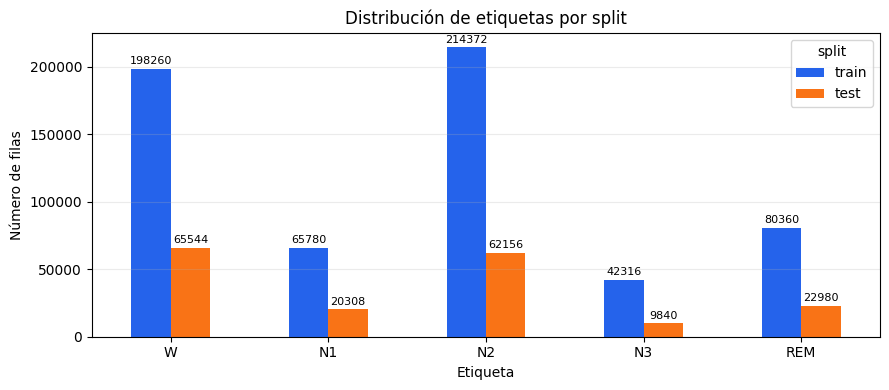

In [48]:


ax = label_distribution_df.plot(
    kind="bar",
    figsize=(9, 4),
    rot=0,
    color=["#2563eb", "#f97316"],
)
ax.set_title("Distribución de etiquetas por split")
ax.set_xlabel("Etiqueta")
ax.set_ylabel("Número de filas")
ax.legend(title="split")
ax.grid(axis="y", alpha=0.25)
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", fontsize=8, padding=2)
plt.tight_layout()
